# THỰC HÀNH: PHÂN TÍCH KHÁM PHÁ DỮ LIỆU
Notebook thực hiện lại toàn bộ code mẫu trong file *Lab - Phân tích khám phá dữ liệu* và các bài tập thực hành.

**Ghi chú về dữ liệu:** các tập dữ liệu Kaggle được đặt trong thư mục `data/`. Một số chỗ code mẫu phải chỉnh nhỏ để chạy được với phiên bản thư viện hiện tại (ví dụ thêm `import`, `sep='\t'` cho file Marketing); các chỗ này được ghi chú bằng `# [Chỉnh]`.

## 1.1. THỐNG KÊ MÔ TẢ
### 1.1.2. Bài làm mẫu — Bài toán 1
#### Nhiệm vụ 1: Khám phá dữ liệu COVID (ourworldindata.org/coronavirus)

In [1]:
import numpy as np
import pandas as pd
from scipy import stats
# Load the .csv into a dataframe using read_csv
covid_data = pd.read_csv("data/covid-data.csv")
covid_data = covid_data[['iso_code','continent',
 'location','date','total_cases','new_cases']]

In [2]:
# Take a quick look at the data
covid_data.head(5)

,iso_code,continent,location,date,total_cases,new_cases
0,AFG,Asia,Afghanistan,2020-01-05,0.0,0.0
1,AFG,Asia,Afghanistan,2020-01-06,0.0,0.0
2,AFG,Asia,Afghanistan,2020-01-07,0.0,0.0
3,AFG,Asia,Afghanistan,2020-01-08,0.0,0.0
4,AFG,Asia,Afghanistan,2020-01-09,0.0,0.0


In [3]:
covid_data.dtypes

iso_code        object
continent       object
location        object
date            object
total_cases    float64
new_cases      float64
dtype: object

In [4]:
covid_data.shape

(429435, 6)

In [5]:
# Get the mean of the data
data_mean = np.mean(covid_data["new_cases"])
# Get the median of the data
data_median = np.median(covid_data["new_cases"])
# Get the mode of the data
data_mode = stats.mode(covid_data["new_cases"])
# Obtain the variance of the data
data_variance = np.var(covid_data["new_cases"])
# Obtain the standard deviation of the data
data_sd = np.std(covid_data["new_cases"])
# Compute the maximum and minimum values of the data
data_max = np.max(covid_data["new_cases"])
data_min = np.min(covid_data["new_cases"])
# Obtain the 60th percentile of the data
data_percentile = np.percentile(covid_data["new_cases"],60)
# Obtain the quartiles of the data
data_quartile = np.quantile(covid_data["new_cases"],0.75)
# Get the IQR of the data
data_IQR = stats.iqr(covid_data["new_cases"])

In [6]:
print("mean      :", data_mean)
print("median    :", data_median)
print("mode      :", data_mode)
print("variance  :", data_variance)
print("std       :", data_sd)
print("max / min :", data_max, "/", data_min)
print("P60       :", data_percentile)
print("Q3        :", data_quartile)
print("IQR       :", data_IQR)

mean      : 8017.359933586731
median    : nan
mode      : ModeResult(mode=np.float64(0.0), count=np.int64(368385))
variance  : 52745822411.59028
std       : 229664.58675988833
max / min : 44236227.0 / 0.0
P60       : nan
Q3        : nan
IQR       : nan


> **Nhận xét:** cột `new_cases` có giá trị thiếu (NaN) nên các hàm của NumPy trả về `nan` (code mẫu giữ nguyên như đề). Ô dưới đây là phần **mở rộng**: bỏ NaN trước khi tính để có số liệu thật.

In [7]:
# [Mở rộng] bỏ giá trị thiếu trước khi tính thống kê
nc = covid_data["new_cases"].dropna()
print("Số dòng thiếu new_cases:", covid_data["new_cases"].isna().sum())
print("mean      :", np.mean(nc))
print("median    :", np.median(nc))
print("mode      :", stats.mode(nc).mode)
print("variance  :", np.var(nc))
print("std       :", np.std(nc))
print("max / min :", np.max(nc), "/", np.min(nc))
print("P60       :", np.percentile(nc,60))
print("Q3        :", np.quantile(nc,0.75))
print("IQR       :", stats.iqr(nc))

Số dòng thiếu new_cases: 19276
mean      : 8017.359933586731
median    : 0.0
mode      : 0.0
variance  : 52745822411.590294
std       : 229664.58675988836
max / min : 44236227.0 / 0.0
P60       : 0.0
Q3        : 0.0
IQR       : 0.0


#### Nhiệm vụ 2: Khám phá và xử lý dữ liệu Marketing Campaign

In [8]:
import pandas as pd
# [Chỉnh] file Marketing Campaign (Kaggle) phân cách bằng dấu Tab nên cần sep='\t'
marketing_data = pd.read_csv("data/marketing_campaign.csv", sep='\t', encoding='utf-8-sig')
# [Chỉnh] tên cột đúng là 'Dt_Customer' (đề in nhầm 'Dt_ Customer')
marketing_data = marketing_data[['ID','Year_Birth', 'Education',
 'Marital_Status','Income','Kidhome', 'Teenhome',
 'Dt_Customer', 'Recency','NumStorePurchases',
 'NumWebVisitsMonth']]

**2. Loại bỏ dữ liệu trùng lặp**

In [9]:
marketing_data.head()

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,NumStorePurchases,NumWebVisitsMonth
0,5524,1957,Graduation,Single,58138.0,0,0,04-09-2012,58,4,7
1,2174,1954,Graduation,Single,46344.0,1,1,08-03-2014,38,2,5
2,4141,1965,Graduation,Together,71613.0,0,0,21-08-2013,26,10,4
3,6182,1984,Graduation,Together,26646.0,1,0,10-02-2014,26,4,6
4,5324,1981,PhD,Married,58293.0,1,0,19-01-2014,94,6,5


In [10]:
# Remove duplicates across the columns in our dataset:
marketing_data_duplicate = marketing_data.drop_duplicates()
print(marketing_data.shape, '->', marketing_data_duplicate.shape)

(2240, 11) -> (2240, 11)


In [11]:
# Delete a specified row at index value 1:
marketing_data.drop(labels=[1], axis=0)

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,NumStorePurchases,NumWebVisitsMonth
0,5524,1957,Graduation,Single,58138.0,0,0,04-09-2012,58,4,7
2,4141,1965,Graduation,Together,71613.0,0,0,21-08-2013,26,10,4
3,6182,1984,Graduation,Together,26646.0,1,0,10-02-2014,26,4,6
4,5324,1981,PhD,Married,58293.0,1,0,19-01-2014,94,6,5
5,7446,1967,Master,Together,62513.0,0,1,09-09-2013,16,10,6
...,...,...,...,...,...,...,...,...,...,...,...
2235,10870,1967,Graduation,Married,61223.0,0,1,13-06-2013,46,4,5
2236,4001,1946,PhD,Together,64014.0,2,1,10-06-2014,56,5,7
2237,7270,1981,Graduation,Divorced,56981.0,0,0,25-01-2014,91,13,6
2238,8235,1956,Master,Together,69245.0,0,1,24-01-2014,8,10,3


In [12]:
# Delete a single column
marketing_data.drop(labels=['Year_Birth'], axis=1)

,ID,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,NumStorePurchases,NumWebVisitsMonth
0,5524,Graduation,Single,58138.0,0,0,04-09-2012,58,4,7
1,2174,Graduation,Single,46344.0,1,1,08-03-2014,38,2,5
2,4141,Graduation,Together,71613.0,0,0,21-08-2013,26,10,4
3,6182,Graduation,Together,26646.0,1,0,10-02-2014,26,4,6
4,5324,PhD,Married,58293.0,1,0,19-01-2014,94,6,5
...,...,...,...,...,...,...,...,...,...,...
2235,10870,Graduation,Married,61223.0,0,1,13-06-2013,46,4,5
2236,4001,PhD,Together,64014.0,2,1,10-06-2014,56,5,7
2237,7270,Graduation,Divorced,56981.0,0,0,25-01-2014,91,13,6
2238,8235,Master,Together,69245.0,0,1,24-01-2014,8,10,3


**3. Thay thế dữ liệu và thay đổi định dạng của dữ liệu**

In [13]:
# Replace the values in Teenhome with has teen and has no teen
marketing_data['Teenhome_replaced'] = marketing_data['Teenhome'].replace([0,1,2],['has no teen','has teen','has teen'])
marketing_data[['Teenhome','Teenhome_replaced']].head()

,Teenhome,Teenhome_replaced
0,0,has no teen
1,1,has teen
2,0,has no teen
3,0,has no teen
4,0,has no teen


In [14]:
# Fill NAs in the Income column
marketing_data['Income'] = marketing_data['Income'].fillna(0)
# Change the data type of the Income column from float to int
marketing_data['Income_changed'] = marketing_data['Income'].astype(int)
marketing_data[['Income','Income_changed']].dtypes

Income            float64
Income_changed      int64
dtype: object

**4. Xử lý dữ liệu thiếu**

In [15]:
# Check for missing values using the isnull and sum methods
marketing_data.isnull().sum()

ID                   0
Year_Birth           0
Education            0
Marital_Status       0
Income               0
Kidhome              0
Teenhome             0
Dt_Customer          0
Recency              0
NumStorePurchases    0
NumWebVisitsMonth    0
Teenhome_replaced    0
Income_changed       0
dtype: int64

In [16]:
# Drop missing values using the dropna method
marketing_data_withoutna = marketing_data.dropna(how = 'any')
marketing_data_withoutna.shape

(2240, 13)

### 1.1.3. Bài tập thực hành 1 — Thống kê mô tả tập dữ liệu chất lượng rượu đỏ

In [17]:
import numpy as np
import pandas as pd
from scipy import stats
wine = pd.read_csv("data/winequality-red.csv", sep=';')
print(wine.shape)
wine.head()

(1599, 12)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


In [18]:
wine.dtypes

fixed acidity           float64
volatile acidity        float64
citric acid             float64
residual sugar          float64
chlorides               float64
free sulfur dioxide     float64
total sulfur dioxide    float64
density                 float64
pH                      float64
sulphates               float64
alcohol                 float64
quality                   int64
dtype: object

In [19]:
wine.isnull().sum()

fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
dtype: int64

In [20]:
wine.describe().T

,count,mean,std,min,25%,50%,75%,max
fixed acidity,1599.0,8.319637,1.741096,4.60000,7.1000,7.90000,9.200000,15.90000
volatile acidity,1599.0,0.527821,0.179060,0.12000,0.3900,0.52000,0.640000,1.58000
citric acid,1599.0,0.270976,0.194801,0.00000,0.0900,0.26000,0.420000,1.00000
residual sugar,1599.0,2.538806,1.409928,0.90000,1.9000,2.20000,2.600000,15.50000
chlorides,1599.0,0.087467,0.047065,0.01200,0.0700,0.07900,0.090000,0.61100
free sulfur dioxide,1599.0,15.874922,10.460157,1.00000,7.0000,14.00000,21.000000,72.00000
total sulfur dioxide,1599.0,46.467792,32.895324,6.00000,22.0000,38.00000,62.000000,289.00000
density,1599.0,0.996747,0.001887,0.99007,0.9956,0.99675,0.997835,1.00369
pH,1599.0,3.311113,0.154386,2.74000,3.2100,3.31000,3.400000,4.01000
sulphates,1599.0,0.658149,0.169507,0.33000,0.5500,0.62000,0.730000,2.00000


In [21]:
# Các thước đo thống kê mô tả cho một số cột (ví dụ: alcohol)
col = wine['alcohol']
print("mean      :", np.mean(col))
print("median    :", np.median(col))
print("mode      :", stats.mode(col).mode)
print("variance  :", np.var(col))
print("std       :", np.std(col))
print("range     :", np.max(col) - np.min(col))
print("P60       :", np.percentile(col, 60))
print("Q1,Q2,Q3  :", np.quantile(col, [0.25, 0.5, 0.75]))
print("IQR       :", stats.iqr(col))
print("skewness  :", stats.skew(col))

mean      : 10.422983114446529
median    : 10.2
mode      : 9.5
variance  : 1.1349371714889036
std       : 1.0653343003437483
range     : 6.5
P60       : 10.5
Q1,Q2,Q3  : [ 9.5 10.2 11.1]
IQR       : 1.5999999999999996
skewness  : 0.8600210646566755


In [22]:
# Phân bố của biến mục tiêu quality và độ lệch (skewness) của các biến
print(wine['quality'].value_counts().sort_index())
wine.skew().sort_values(ascending=False)

quality
3     10
4     53
5    681
6    638
7    199
8     18
Name: count, dtype: int64


chlorides               5.680347
residual sugar          4.540655
sulphates               2.428672
total sulfur dioxide    1.515531
free sulfur dioxide     1.250567
fixed acidity           0.982751
alcohol                 0.860829
volatile acidity        0.671593
citric acid             0.318337
quality                 0.217802
pH                      0.193683
density                 0.071288
dtype: float64

In [23]:
# Phát hiện ngoại lai bằng quy tắc 1.5*IQR
Q1 = wine.quantile(0.25); Q3 = wine.quantile(0.75); IQR = Q3 - Q1
outliers = ((wine < (Q1 - 1.5*IQR)) | (wine > (Q3 + 1.5*IQR))).sum()
outliers.sort_values(ascending=False)

residual sugar          155
chlorides               112
sulphates                59
total sulfur dioxide     55
fixed acidity            49
density                  45
pH                       35
free sulfur dioxide      30
quality                  28
volatile acidity         19
alcohol                  13
citric acid               1
dtype: int64

### 1.1.4. Bài tập thực hành 2 — Thống kê mô tả tập dữ liệu bệnh tiểu đường (Pima Indians)

In [24]:
diabetes = pd.read_csv("data/diabetes.csv")
print(diabetes.shape)
diabetes.head()

(768, 9)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [25]:
diabetes.describe().T

,count,mean,std,min,25%,50%,75%,max
Pregnancies,768.0,3.845052,3.369578,0.000,1.00000,3.0000,6.00000,17.00
Glucose,768.0,120.894531,31.972618,0.000,99.00000,117.0000,140.25000,199.00
BloodPressure,768.0,69.105469,19.355807,0.000,62.00000,72.0000,80.00000,122.00
SkinThickness,768.0,20.536458,15.952218,0.000,0.00000,23.0000,32.00000,99.00
Insulin,768.0,79.799479,115.244002,0.000,0.00000,30.5000,127.25000,846.00
BMI,768.0,31.992578,7.884160,0.000,27.30000,32.0000,36.60000,67.10
DiabetesPedigreeFunction,768.0,0.471876,0.331329,0.078,0.24375,0.3725,0.62625,2.42
Age,768.0,33.240885,11.760232,21.000,24.00000,29.0000,41.00000,81.00
Outcome,768.0,0.348958,0.476951,0.000,0.00000,0.0000,1.00000,1.00


In [26]:
# Trong dữ liệu Pima, giá trị 0 ở các cột dưới đây thực chất là dữ liệu thiếu
cols0 = ['Glucose','BloodPressure','SkinThickness','Insulin','BMI']
print((diabetes[cols0] == 0).sum())

Glucose            5
BloodPressure     35
SkinThickness    227
Insulin          374
BMI               11
dtype: int64


In [27]:
# Xử lý dữ liệu thiếu: thay 0 bằng NaN rồi điền bằng median của từng cột
diabetes_clean = diabetes.copy()
diabetes_clean[cols0] = diabetes_clean[cols0].replace(0, np.nan)
diabetes_clean[cols0] = diabetes_clean[cols0].fillna(diabetes_clean[cols0].median())
diabetes_clean.describe().T

,count,mean,std,min,25%,50%,75%,max
Pregnancies,768.0,3.845052,3.369578,0.000,1.00000,3.0000,6.00000,17.00
Glucose,768.0,121.656250,30.438286,44.000,99.75000,117.0000,140.25000,199.00
BloodPressure,768.0,72.386719,12.096642,24.000,64.00000,72.0000,80.00000,122.00
SkinThickness,768.0,29.108073,8.791221,7.000,25.00000,29.0000,32.00000,99.00
Insulin,768.0,140.671875,86.383060,14.000,121.50000,125.0000,127.25000,846.00
BMI,768.0,32.455208,6.875177,18.200,27.50000,32.3000,36.60000,67.10
DiabetesPedigreeFunction,768.0,0.471876,0.331329,0.078,0.24375,0.3725,0.62625,2.42
Age,768.0,33.240885,11.760232,21.000,24.00000,29.0000,41.00000,81.00
Outcome,768.0,0.348958,0.476951,0.000,0.00000,0.0000,1.00000,1.00


In [28]:
print("Phân bố nhãn Outcome:"); print(diabetes['Outcome'].value_counts())
print()
print("Trung bình theo nhóm Outcome:")
diabetes_clean.groupby('Outcome').mean().T

Phân bố nhãn Outcome:
Outcome
0    500
1    268
Name: count, dtype: int64

Trung bình theo nhóm Outcome:


Outcome,0,1
Pregnancies,3.298000,4.865672
Glucose,110.682000,142.130597
BloodPressure,70.920000,75.123134
SkinThickness,27.726000,31.686567
Insulin,127.792000,164.701493
BMI,30.885600,35.383582
DiabetesPedigreeFunction,0.429734,0.550500
Age,31.190000,37.067164


## 1.2. XỬ LÝ VÀ TRỰC QUAN HÓA DỮ LIỆU
### 1.2.2. Bài làm mẫu — Bài toán 1: dữ liệu giá nhà Amsterdam
> **Lưu ý:** dữ liệu giá nhà là file `HousingPrices-Amsterdam-August-2021.csv` tải từ Kaggle (*thomasnibb/amsterdam-house-price-prediction*), đổi tên thành `data/HousingPricesData.csv` cho khớp code mẫu.

In [29]:
import os
HAS_HOUSE = os.path.exists("data/HousingPricesData.csv")
print("Có file HousingPricesData.csv:", HAS_HOUSE)

Có file HousingPricesData.csv: True


In [30]:
import pandas as pd
import matplotlib.pyplot as plt  # [Chỉnh] bổ sung import (đề chưa import ở mục này)
houseprices_data = pd.read_csv("data/HousingPricesData.csv")
houseprices_data = houseprices_data[['Zip', 'Price', 'Area', 'Room']]
# Create a PriceperSqm variable based on the Price and Area variables:
houseprices_data['PriceperSqm'] = houseprices_data['Price']/houseprices_data['Area']

In [31]:
houseprices_sorted = houseprices_data.sort_values('Price', ascending = False)
houseprices_sorted.head()

,Zip,Price,Area,Room,PriceperSqm
195,1017 EL,5950000.0,394,10,15101.522843
837,1075 AH,5850000.0,480,14,12187.500000
305,1016 AE,4900000.0,623,13,7865.168539
103,1017 ZP,4550000.0,497,13,9154.929577
179,1012 JS,4495000.0,178,5,25252.808989


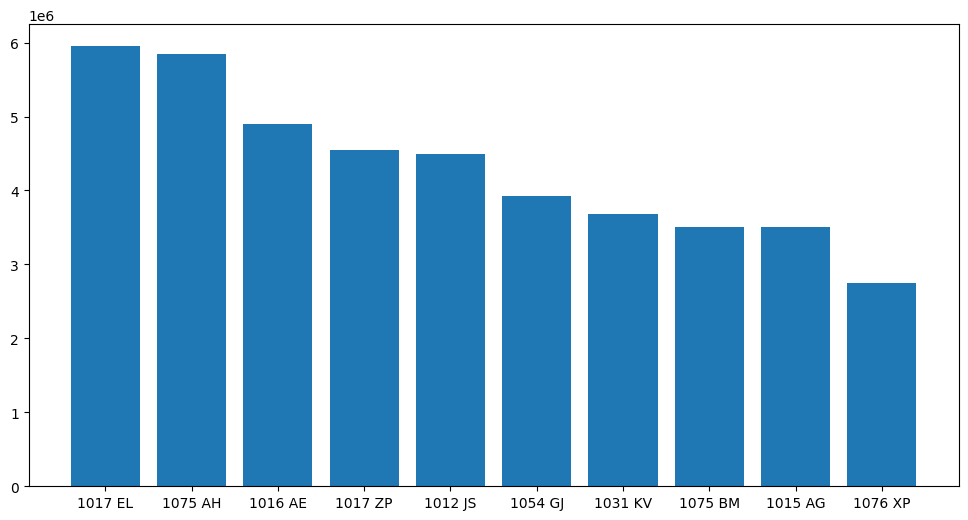

In [32]:
# case 1: basic
plt.figure(figsize= (12,6))
x = houseprices_sorted['Zip'][0:10]
y = houseprices_sorted['Price'][0:10]
plt.bar(x,y)
plt.show()

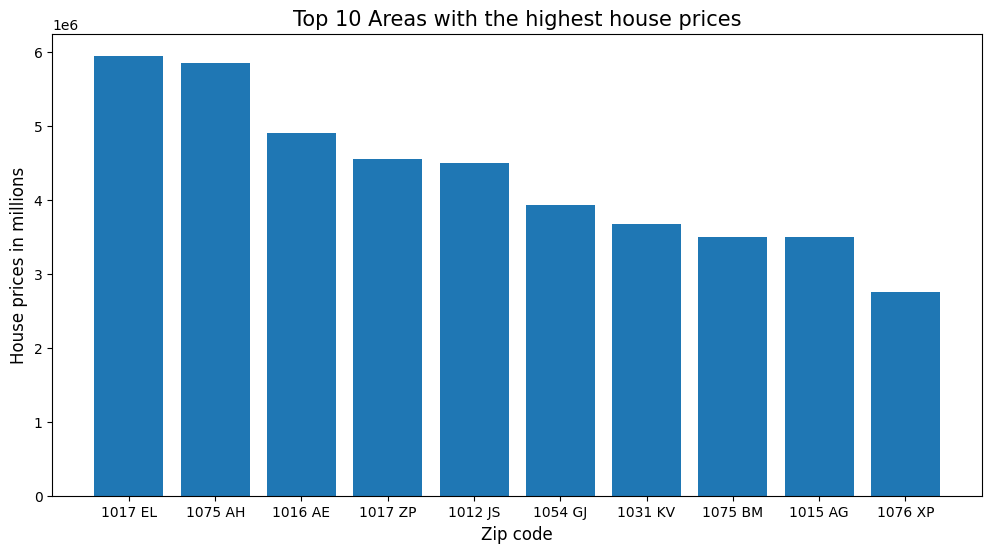

In [33]:
# case 2: advanced 1
plt.figure(figsize= (12,6))
plt.bar(x,y)
plt.title('Top 10 Areas with the highest house prices', fontsize=15)
plt.xlabel('Zip code', fontsize = 12)
plt.xticks(fontsize=10)
plt.ylabel('House prices in millions', fontsize=12)
plt.yticks(fontsize=10)
plt.show()

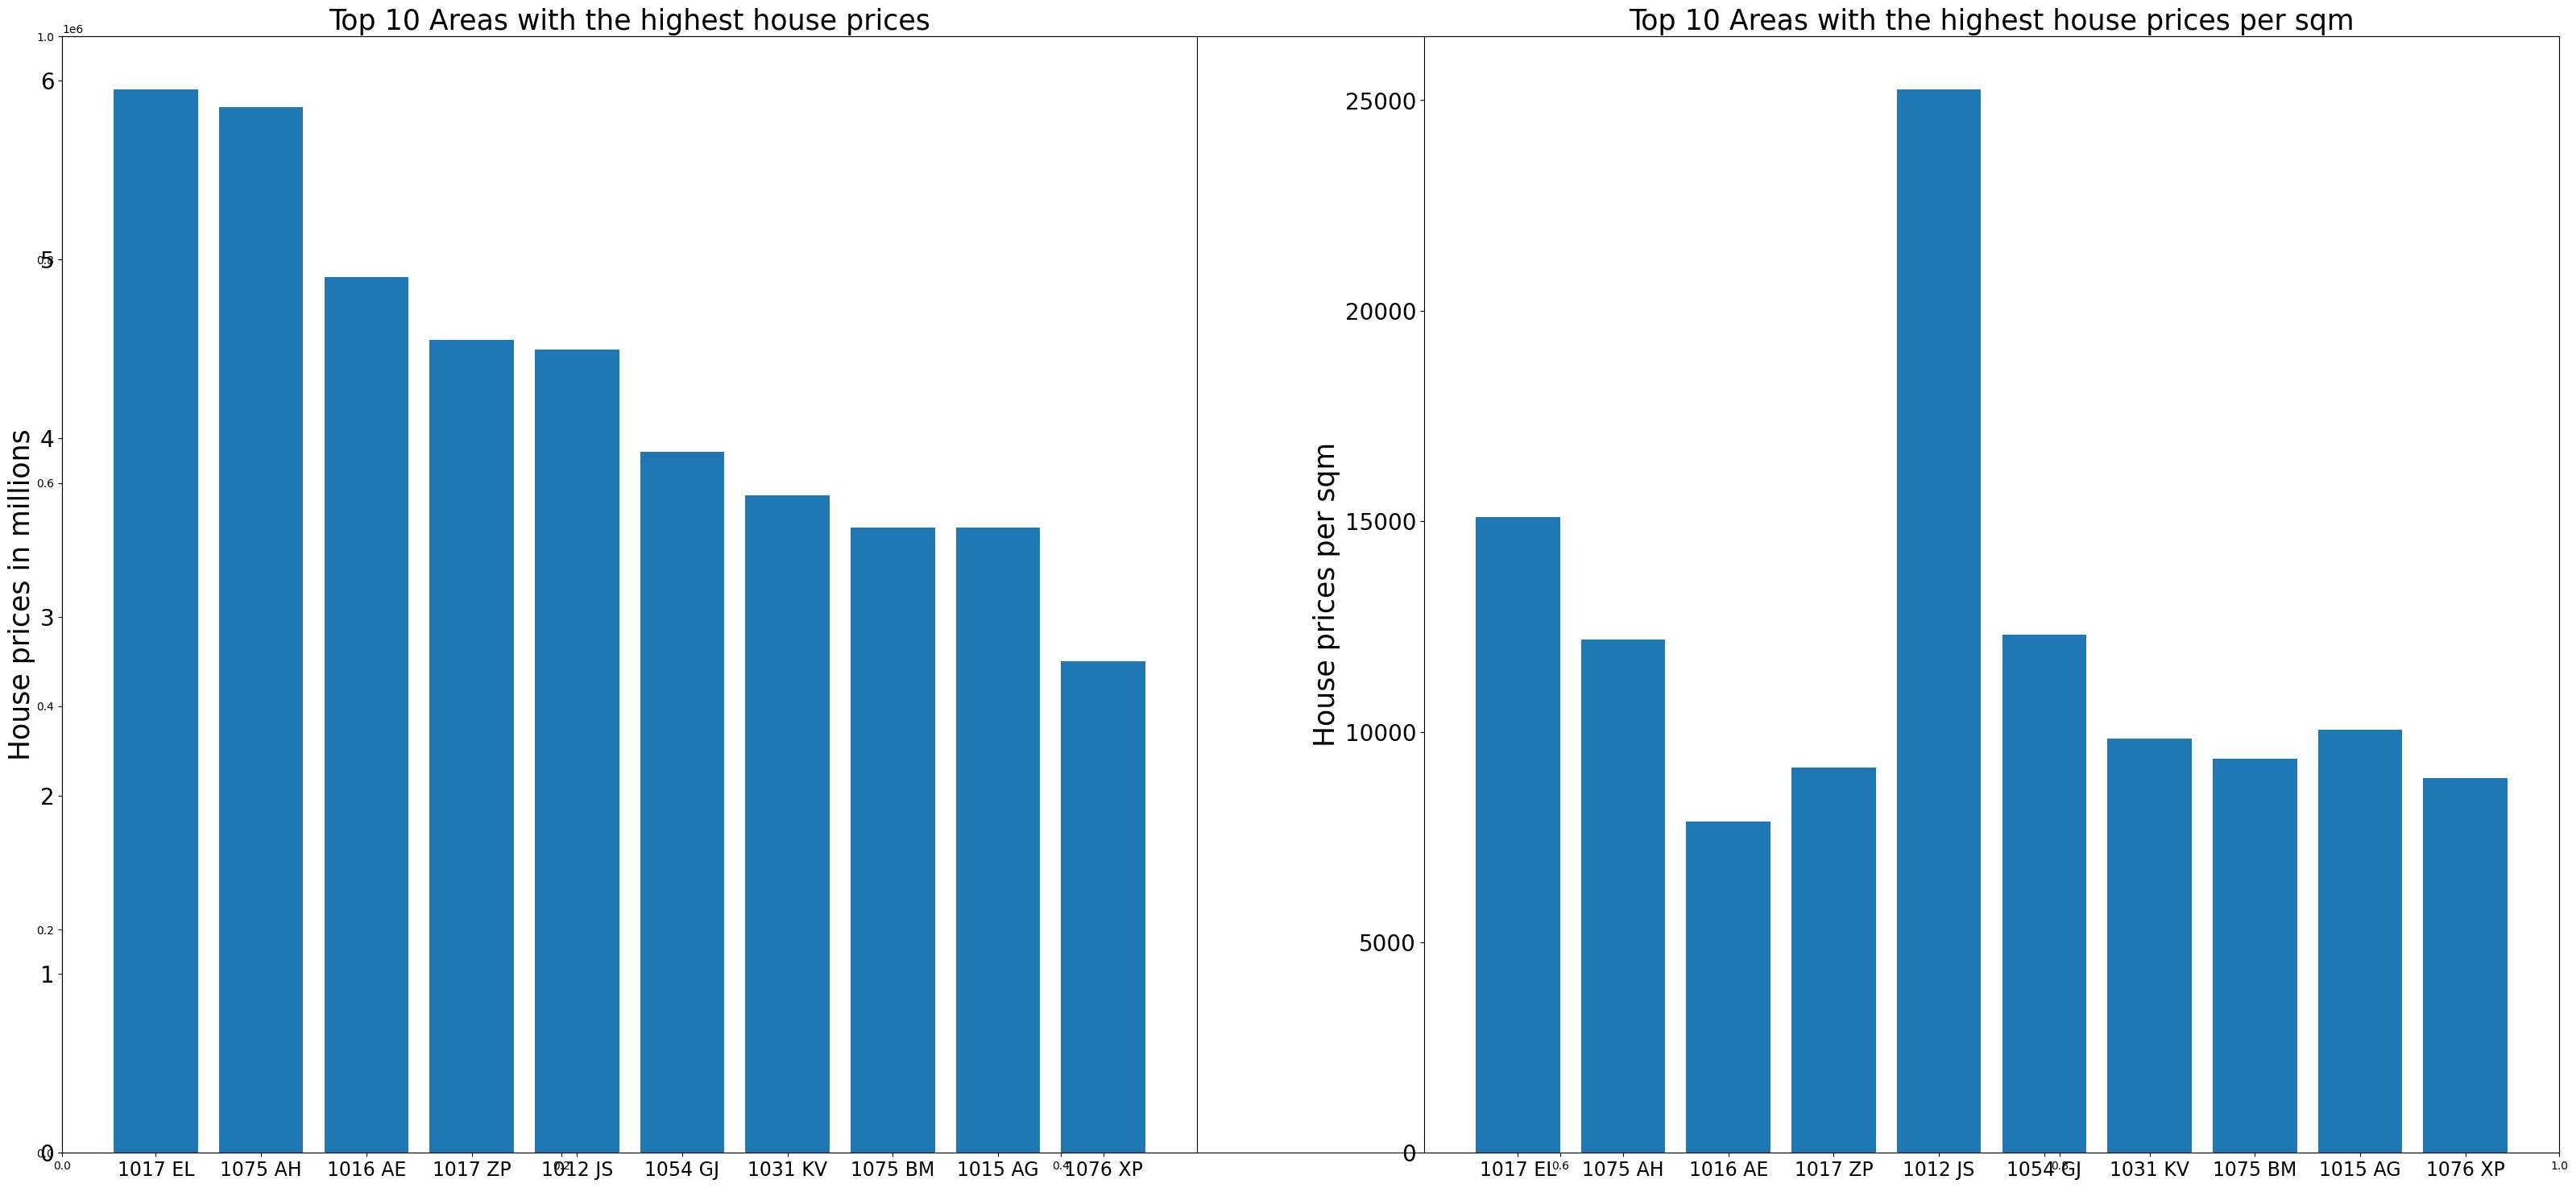

In [34]:
# case 3: advanced 2
fig, ax = plt.subplots(figsize=(40,18))
x = houseprices_sorted['Zip'][0:10]
y = houseprices_sorted['Price'][0:10]
y1 = houseprices_sorted['PriceperSqm'][0:10]
plt.subplot(1,2,1)
plt.bar(x,y)
plt.xticks(fontsize=17)
plt.ylabel('House prices in millions', fontsize=25)
plt.yticks(fontsize=20)
plt.title('Top 10 Areas with the highest house prices', fontsize=25)
plt.subplot(1,2,2)
plt.bar(x,y1)
plt.xticks(fontsize=17)
plt.ylabel('House prices per sqm', fontsize=25)
plt.yticks(fontsize=20)
plt.title('Top 10 Areas with the highest house prices per sqm', fontsize=25)
plt.show()

**3. Trực quan hóa dữ liệu với thư viện Seaborn**

<Axes: xlabel='Zip', ylabel='Price'>

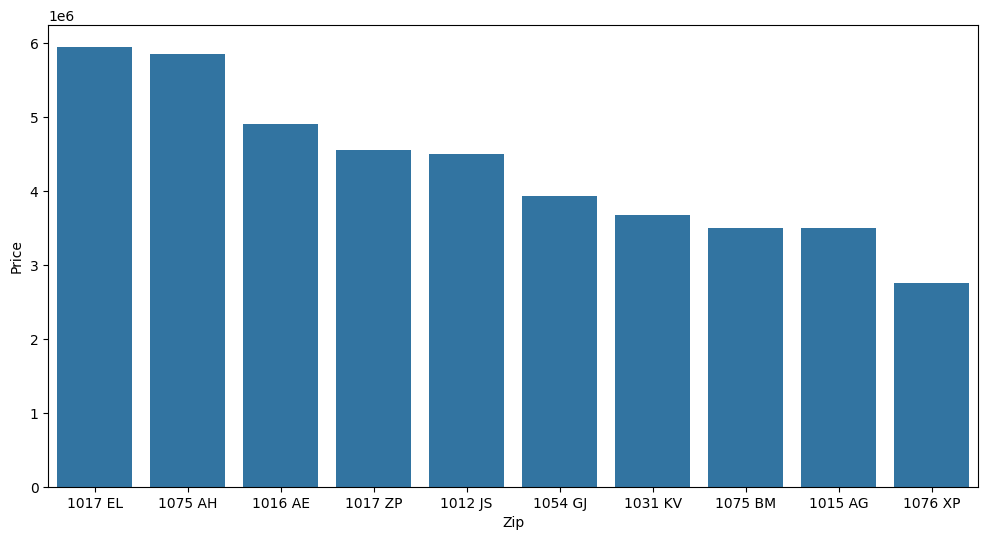

In [35]:
import matplotlib.pyplot as plt
import seaborn as sns
# case 1: basic
plt.figure(figsize= (12,6))
data = houseprices_sorted[0:10]
sns.barplot(data= data, x= 'Zip',y = 'Price')

Text(0.5, 1.0, 'Top 10 Areas with the highest house prices')

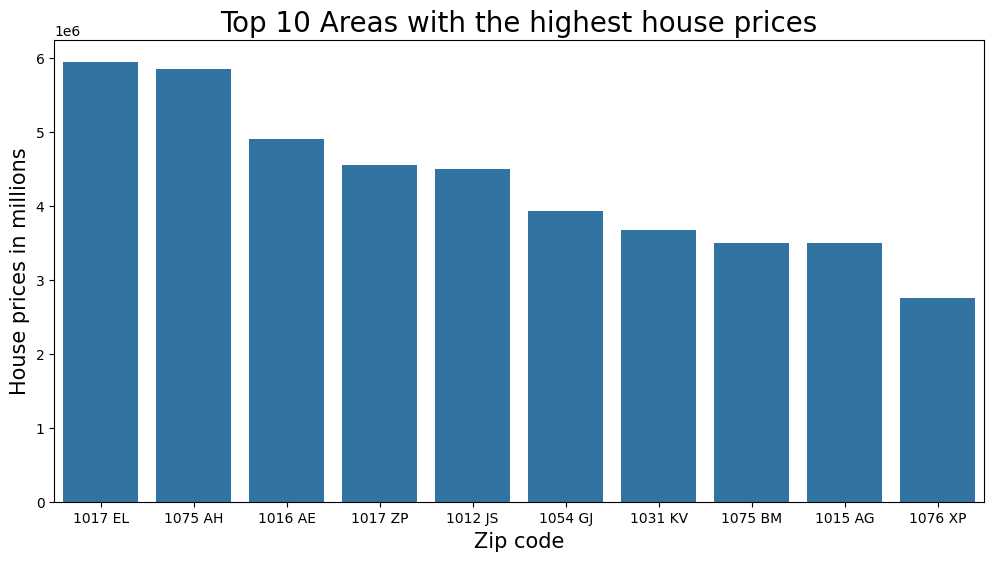

In [36]:
# case 2: advanced 1
plt.figure(figsize= (12,6))
data = houseprices_sorted[0:10]
ax = sns.barplot(data= data, x= 'Zip',y = 'Price')
ax.set_xlabel('Zip code',fontsize = 15)
ax.set_ylabel('House prices in millions', fontsize = 15)
ax.set_title('Top 10 Areas with the highest house prices', fontsize= 20)

Text(0.5, 1.0, 'Top 10 Areas with the highest price per sqm')

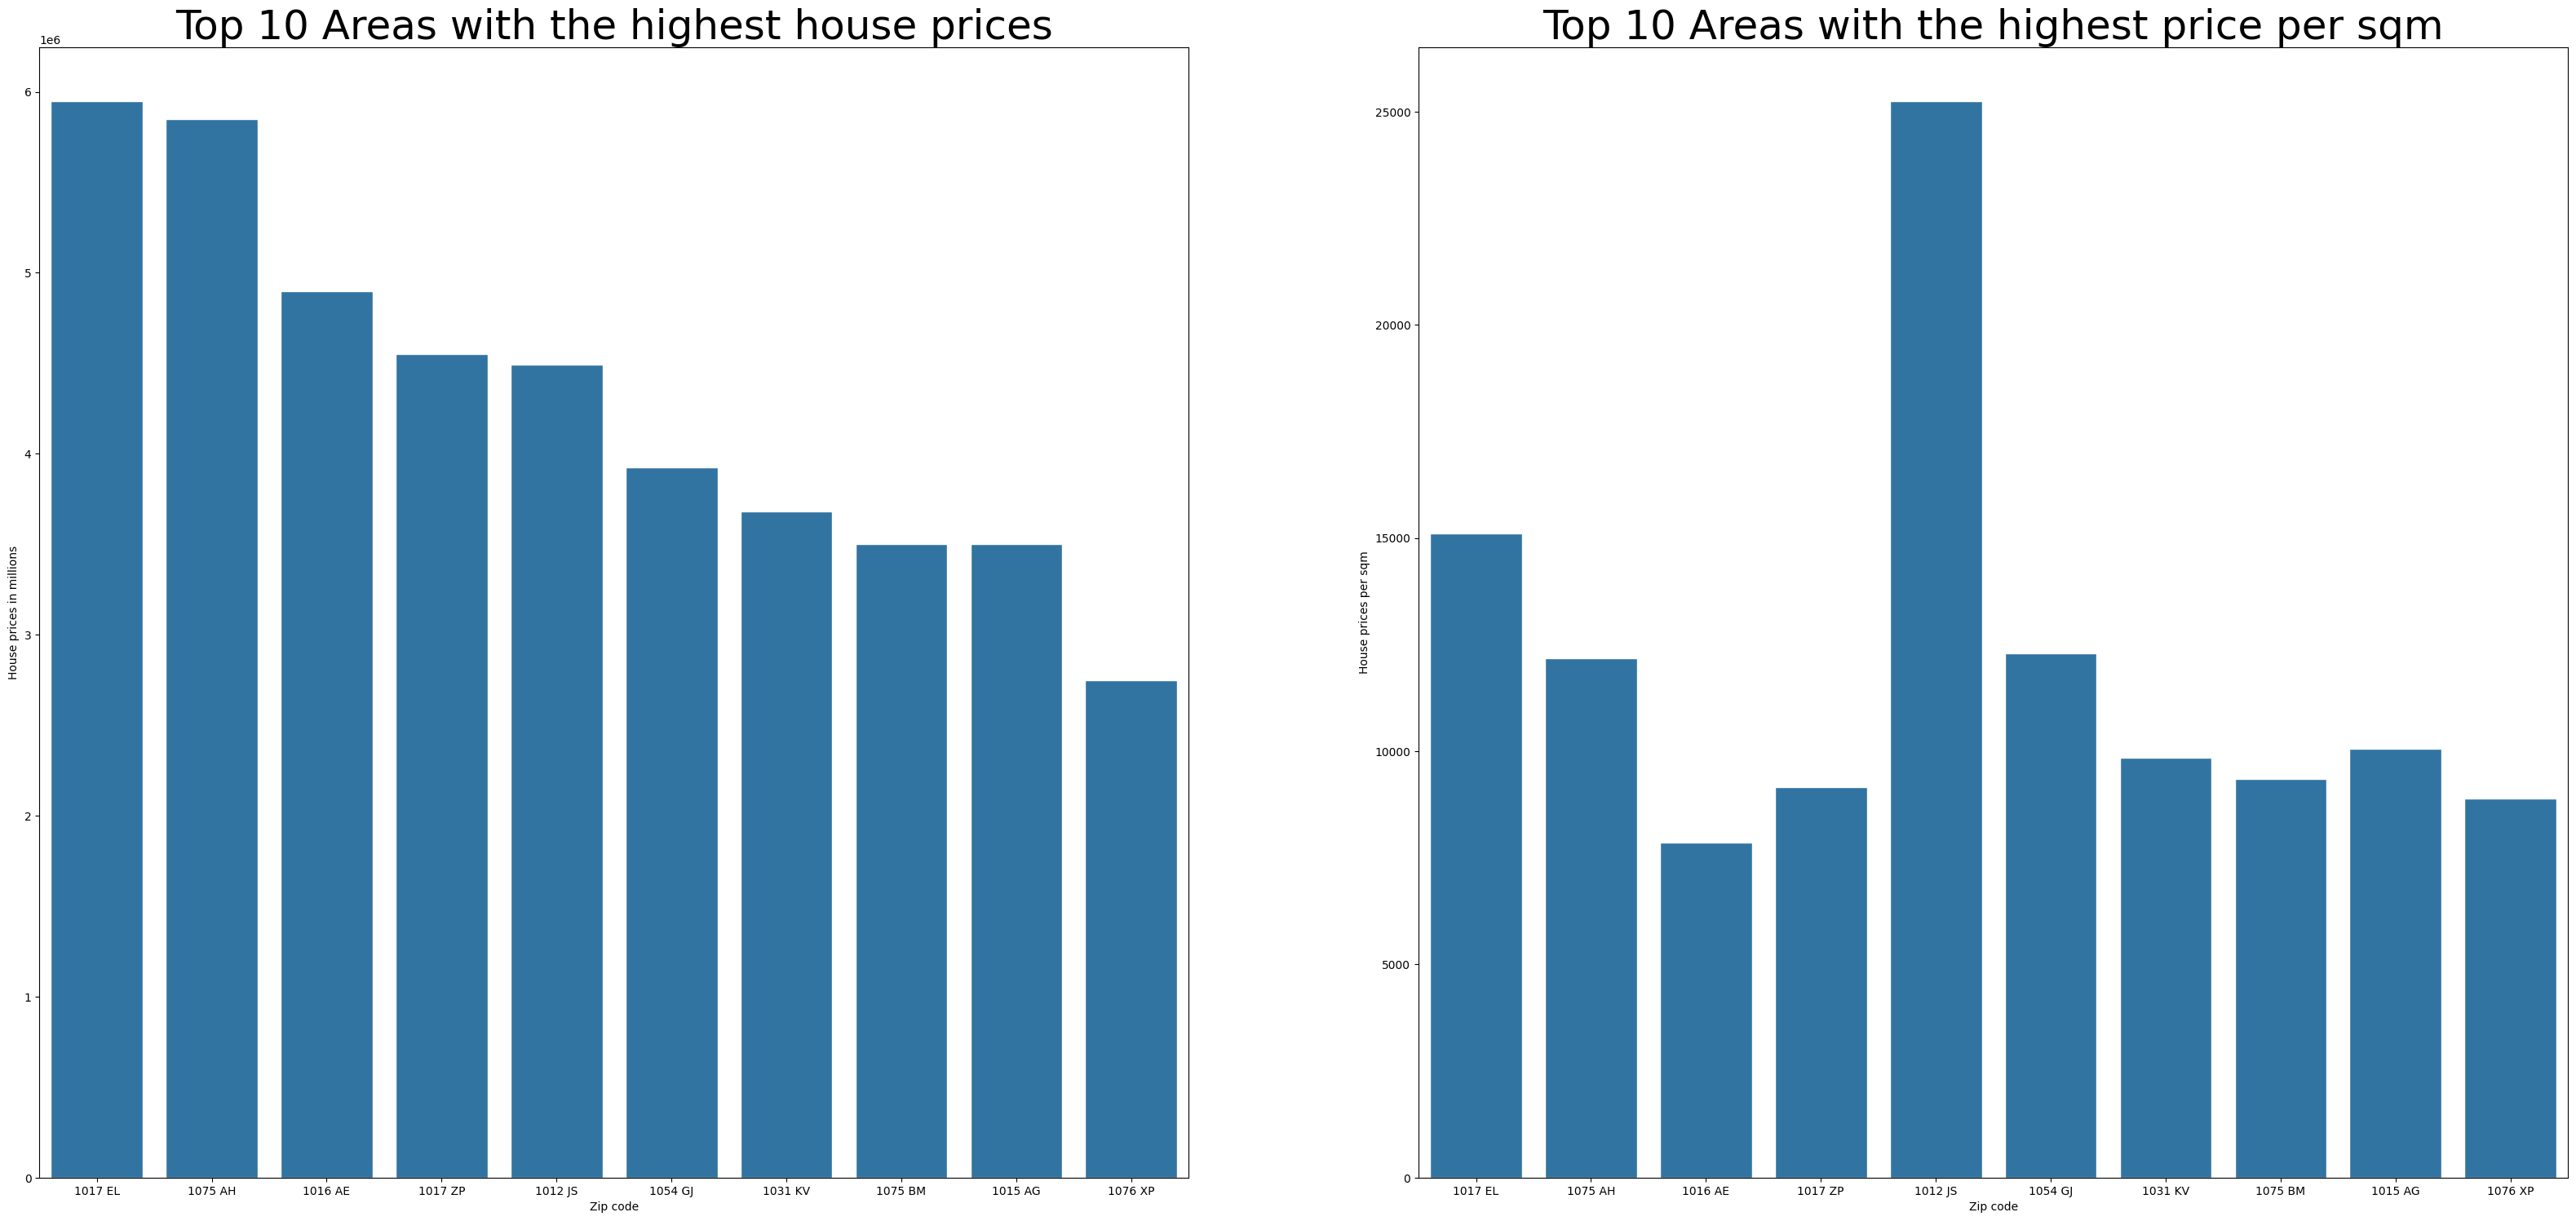

In [37]:
# case 3: view multiple perspectives at once
fig, ax = plt.subplots(1, 2,figsize=(40,18))
data = houseprices_sorted[0:10]
sns.set(font_scale = 3)
ax1 = sns.barplot(data= data, x= 'Zip',y = 'Price', ax = ax[0])
ax1.set_xlabel('Zip code')
ax1.set_ylabel('House prices in millions')
ax1.set_title('Top 10 Areas with the highest house prices')
ax2 = sns.barplot(data= data, x= 'Zip',y = 'PriceperSqm',
ax=ax[1])
ax2.set_xlabel('Zip code')
ax2.set_ylabel('House prices per sqm')
ax2.set_title('Top 10 Areas with the highest price per sqm')

### 1.2.2 / 1.2.3. Bài tập thực hành — Trực quan hóa dữ liệu rượu đỏ và bệnh tiểu đường

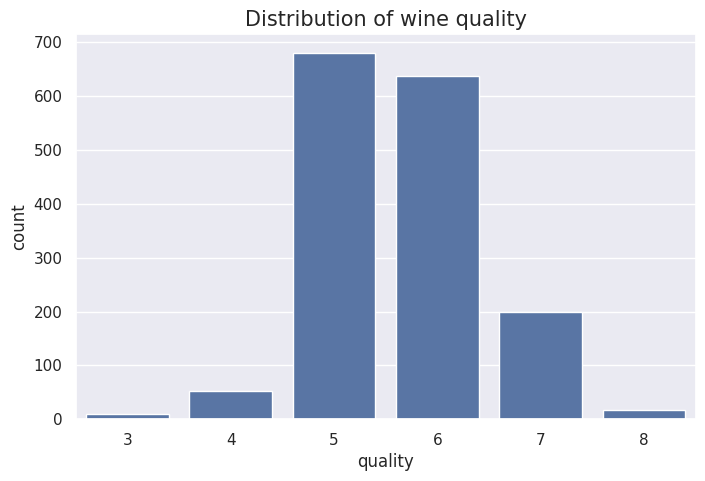

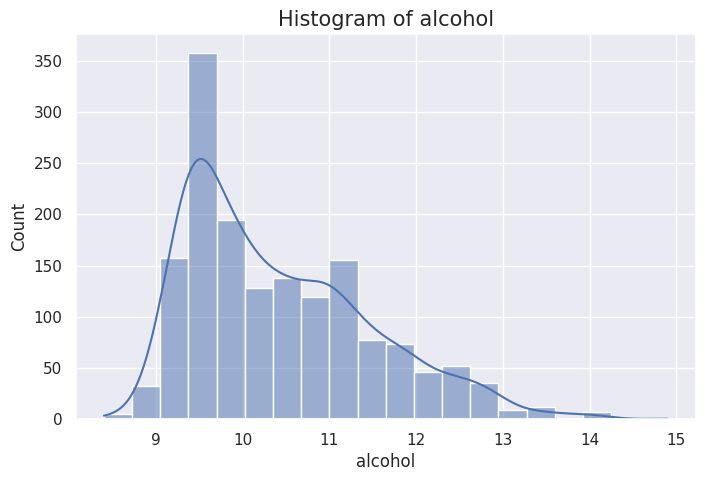

In [38]:
import matplotlib.pyplot as plt
import seaborn as sns
sns.set()   # đưa style về mặc định sau khi đặt font_scale ở trên
wine = pd.read_csv("data/winequality-red.csv", sep=';')

# 1. Biểu đồ cột: phân bố chất lượng rượu
plt.figure(figsize=(8,5))
ax = sns.countplot(data=wine, x='quality')
ax.set_title('Distribution of wine quality', fontsize=15)
plt.show()

# 2. Histogram của nồng độ cồn
plt.figure(figsize=(8,5))
ax = sns.histplot(data=wine, x='alcohol', bins=20, kde=True)
ax.set_title('Histogram of alcohol', fontsize=15)
plt.show()

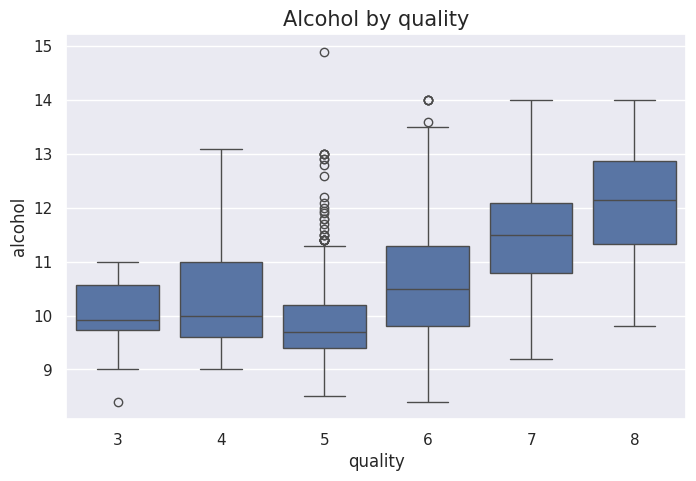

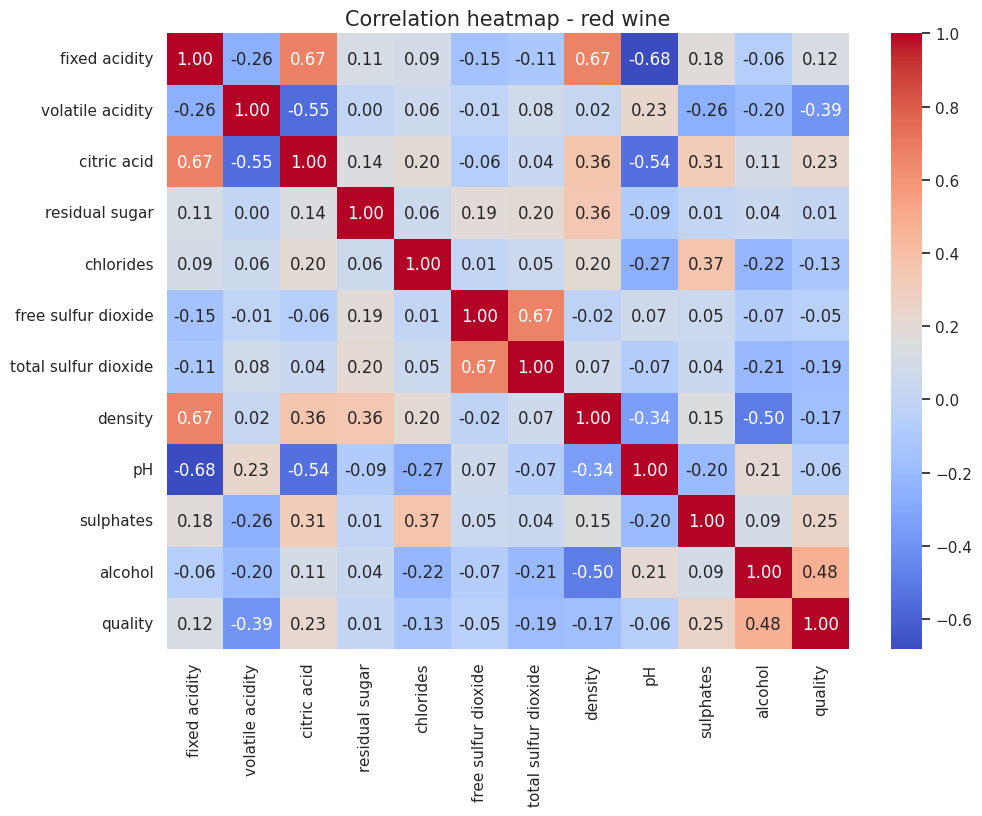

In [39]:
# 3. Boxplot alcohol theo quality (biến số vs biến phân loại)
plt.figure(figsize=(8,5))
ax = sns.boxplot(data=wine, x='quality', y='alcohol')
ax.set_title('Alcohol by quality', fontsize=15)
plt.show()

# 4. Heatmap tương quan giữa các biến
plt.figure(figsize=(11,8))
ax = sns.heatmap(wine.corr(), annot=True, fmt='.2f', cmap='coolwarm')
ax.set_title('Correlation heatmap - red wine', fontsize=15)
plt.show()

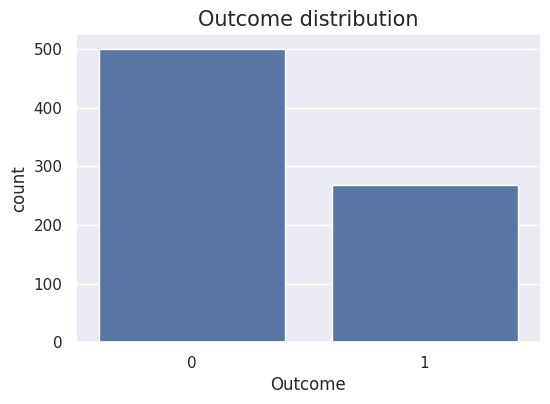

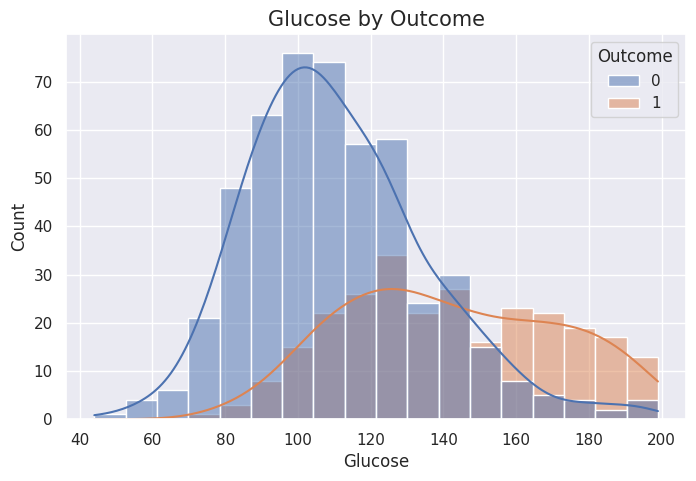

In [40]:
diabetes = pd.read_csv("data/diabetes.csv")
cols0 = ['Glucose','BloodPressure','SkinThickness','Insulin','BMI']
diabetes[cols0] = diabetes[cols0].replace(0, np.nan)
diabetes[cols0] = diabetes[cols0].fillna(diabetes[cols0].median())

# 1. Số lượng người bệnh / không bệnh
plt.figure(figsize=(6,4))
ax = sns.countplot(data=diabetes, x='Outcome')
ax.set_title('Outcome distribution', fontsize=15)
plt.show()

# 2. Histogram Glucose theo Outcome
plt.figure(figsize=(8,5))
ax = sns.histplot(data=diabetes, x='Glucose', hue='Outcome', kde=True)
ax.set_title('Glucose by Outcome', fontsize=15)
plt.show()

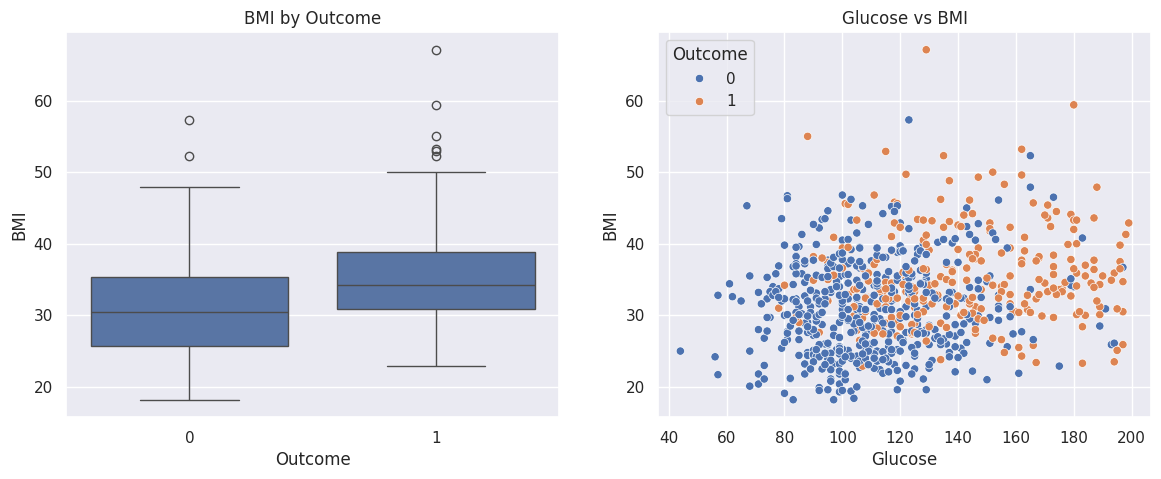

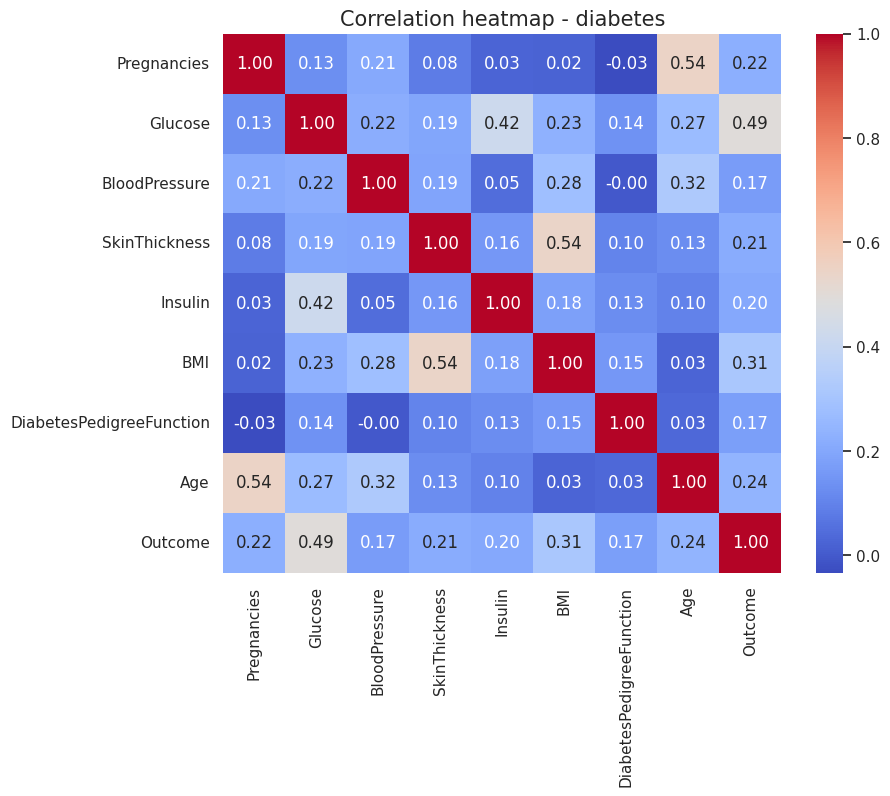

In [41]:
# 3. Boxplot BMI theo Outcome và scatter Glucose - BMI
fig, axes = plt.subplots(1, 2, figsize=(14,5))
sns.boxplot(data=diabetes, x='Outcome', y='BMI', ax=axes[0]).set_title('BMI by Outcome')
sns.scatterplot(data=diabetes, x='Glucose', y='BMI', hue='Outcome', ax=axes[1]).set_title('Glucose vs BMI')
plt.show()

# 4. Heatmap tương quan
plt.figure(figsize=(9,7))
ax = sns.heatmap(diabetes.corr(), annot=True, fmt='.2f', cmap='coolwarm')
ax.set_title('Correlation heatmap - diabetes', fontsize=15)
plt.show()

**EDA tập dữ liệu mua sắm siêu thị (Online Retail, Kaggle)** — file `Online_Retail.xlsx`

In [42]:
import pandas as pd, matplotlib.pyplot as plt, seaborn as sns
sns.set()
retail = pd.read_excel("data/Online_Retail.xlsx")
print(retail.shape)
retail.head()

(541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [43]:
retail.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB


In [44]:
print(retail.isnull().sum())
print("Số dòng trùng lặp:", retail.duplicated().sum())
retail.describe()

InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64


Số dòng trùng lặp: 5268


,Quantity,InvoiceDate,UnitPrice,CustomerID
count,541909.000000,541909,541909.000000,406829.000000
mean,9.552250,2011-07-04 13:34:57.156386048,4.611114,15287.690570
min,-80995.000000,2010-12-01 08:26:00,-11062.060000,12346.000000
25%,1.000000,2011-03-28 11:34:00,1.250000,13953.000000
50%,3.000000,2011-07-19 17:17:00,2.080000,15152.000000
75%,10.000000,2011-10-19 11:27:00,4.130000,16791.000000
max,80995.000000,2011-12-09 12:50:00,38970.000000,18287.000000
std,218.081158,NaN,96.759853,1713.600303


Dữ liệu có đơn hàng bị hủy (InvoiceNo bắt đầu bằng chữ C, Quantity âm) và giá/số lượng không hợp lệ; lọc các dòng này trước khi tính doanh thu.

In [45]:
print("Đơn bị hủy:", retail['InvoiceNo'].astype(str).str.startswith('C').sum())
print("Quantity <= 0:", (retail['Quantity'] <= 0).sum(), "| UnitPrice <= 0:", (retail['UnitPrice'] <= 0).sum())
clean = retail[(retail['Quantity'] > 0) & (retail['UnitPrice'] > 0)].drop_duplicates().copy()
clean['Revenue'] = clean['Quantity'] * clean['UnitPrice']
clean['Month'] = clean['InvoiceDate'].dt.to_period('M').astype(str)
print(clean.shape)

Đơn bị hủy: 9288
Quantity <= 0: 10624 | UnitPrice <= 0: 2517


(524878, 10)


Country
United Kingdom    9001744.094
Netherlands        285446.340
EIRE               283140.520
Germany            228678.400
France             209625.370
Australia          138453.810
Spain               61558.560
Switzerland         57067.600
Belgium             41196.340
Sweden              38367.830
Name: Revenue, dtype: float64


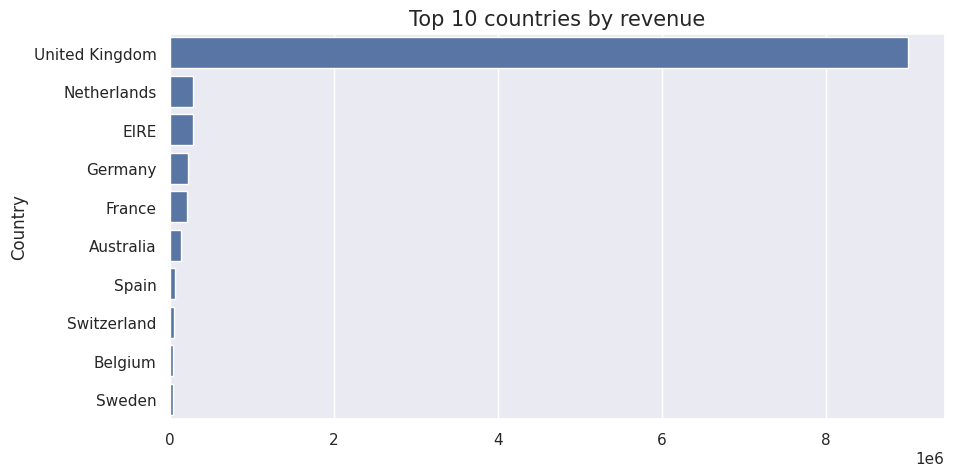

In [46]:
# 10 quốc gia có doanh thu cao nhất
top_country = clean.groupby('Country')['Revenue'].sum().sort_values(ascending=False).head(10)
print(top_country)
plt.figure(figsize=(10,5))
ax = sns.barplot(x=top_country.values, y=top_country.index)
ax.set_title('Top 10 countries by revenue', fontsize=15)
plt.show()

Description
PAPER CRAFT , LITTLE BIRDIE           80995
MEDIUM CERAMIC TOP STORAGE JAR        78033
WORLD WAR 2 GLIDERS ASSTD DESIGNS     54951
JUMBO BAG RED RETROSPOT               48371
WHITE HANGING HEART T-LIGHT HOLDER    37872
POPCORN HOLDER                        36749
PACK OF 72 RETROSPOT CAKE CASES       36396
ASSORTED COLOUR BIRD ORNAMENT         36362
RABBIT NIGHT LIGHT                    30739
MINI PAINT SET VINTAGE                26633
Name: Quantity, dtype: int64


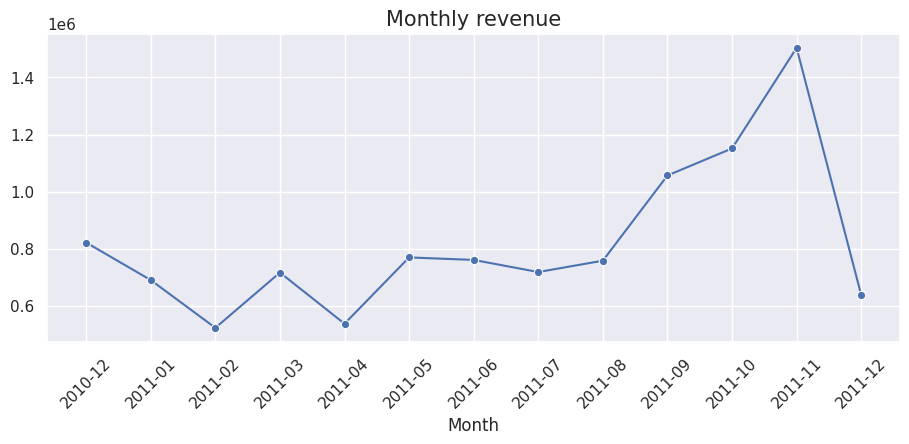

In [47]:
# 10 sản phẩm bán nhiều nhất và doanh thu theo tháng
top_prod = clean.groupby('Description')['Quantity'].sum().sort_values(ascending=False).head(10)
print(top_prod)
monthly = clean.groupby('Month')['Revenue'].sum()
plt.figure(figsize=(11,4))
ax = sns.lineplot(x=monthly.index, y=monthly.values, marker='o')
ax.set_title('Monthly revenue', fontsize=15)
plt.xticks(rotation=45)
plt.show()

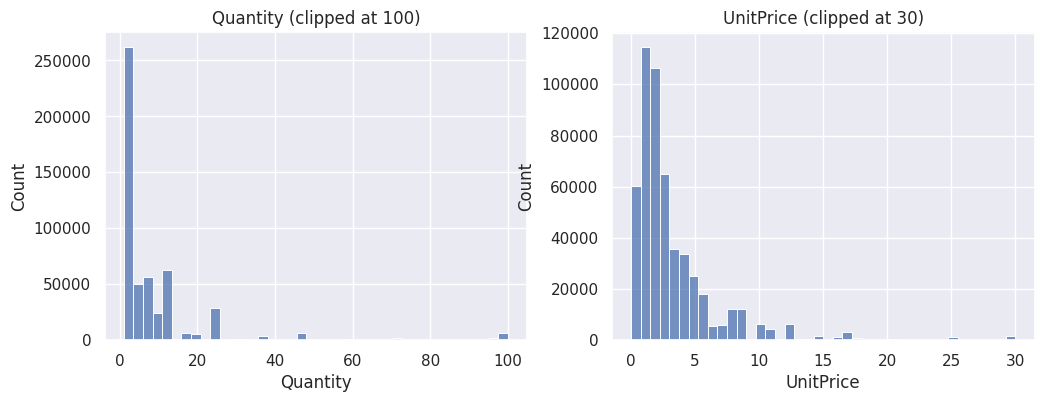

In [48]:
# Phân bố số lượng và đơn giá (thang log do lệch phải mạnh)
fig, axes = plt.subplots(1, 2, figsize=(12,4))
sns.histplot(clean['Quantity'].clip(upper=100), bins=40, ax=axes[0]).set_title('Quantity (clipped at 100)')
sns.histplot(clean['UnitPrice'].clip(upper=30), bins=40, ax=axes[1]).set_title('UnitPrice (clipped at 30)')
plt.show()

## 1.3. PHÂN TÍCH ĐƠN BIẾN VÀ HAI BIẾN
### 1.3.2. Bài làm mẫu — Bài toán 1: phân tích đơn biến
#### Nhiệm vụ 1: dữ liệu chim cánh cụt (Palmer Penguins)

In [49]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
sns.set()
penguins_data = pd.read_csv("data/penguins_size.csv")
penguins_data = penguins_data[['species','culmen_length_mm']]

**2. Phân tích đơn biến bằng Histogram**

<Axes: xlabel='culmen_length_mm', ylabel='Count'>

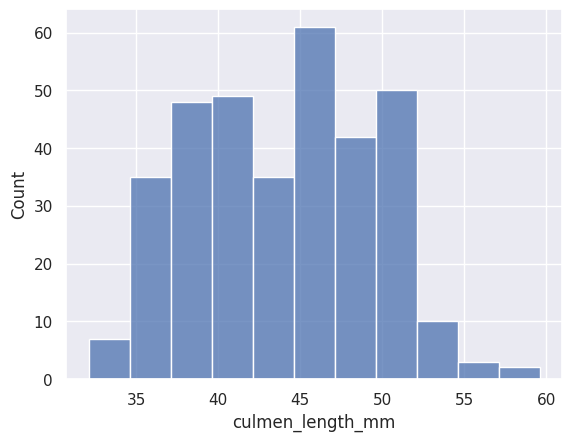

In [50]:
# case 1: basic
sns.histplot( data = penguins_data, x= penguins_data["culmen_length_mm"])

Text(0.5, 1.0, 'Univariate analysis of Culmen Length')

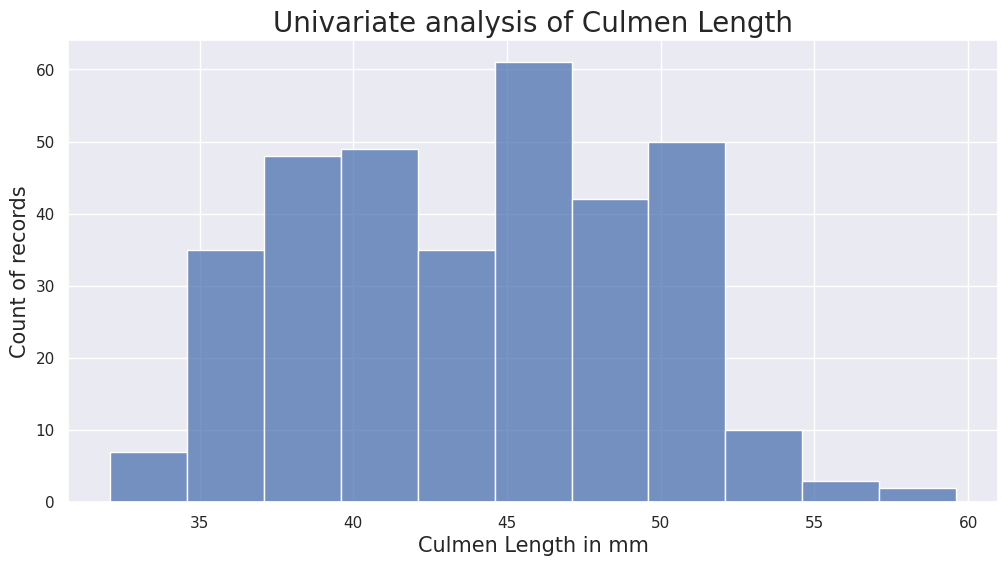

In [51]:
# case 2: advanced
plt.figure(figsize= (12,6))
ax = sns.histplot( data = penguins_data, x= penguins_data["culmen_length_mm"])
ax.set_xlabel('Culmen Length in mm',fontsize = 15)
ax.set_ylabel('Count of records', fontsize = 15)
ax.set_title('Univariate analysis of Culmen Length',fontsize= 20)

**3. Phân tích đơn biến bằng bar chart**

<Axes: xlabel='species', ylabel='count'>

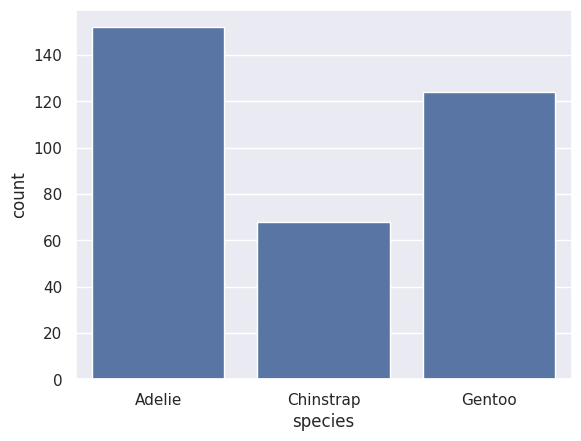

In [52]:
# case 1: basic
sns.countplot(data = penguins_data, x= penguins_data['species'])

Text(0.5, 1.0, 'Univariate analysis of Penguin Species')

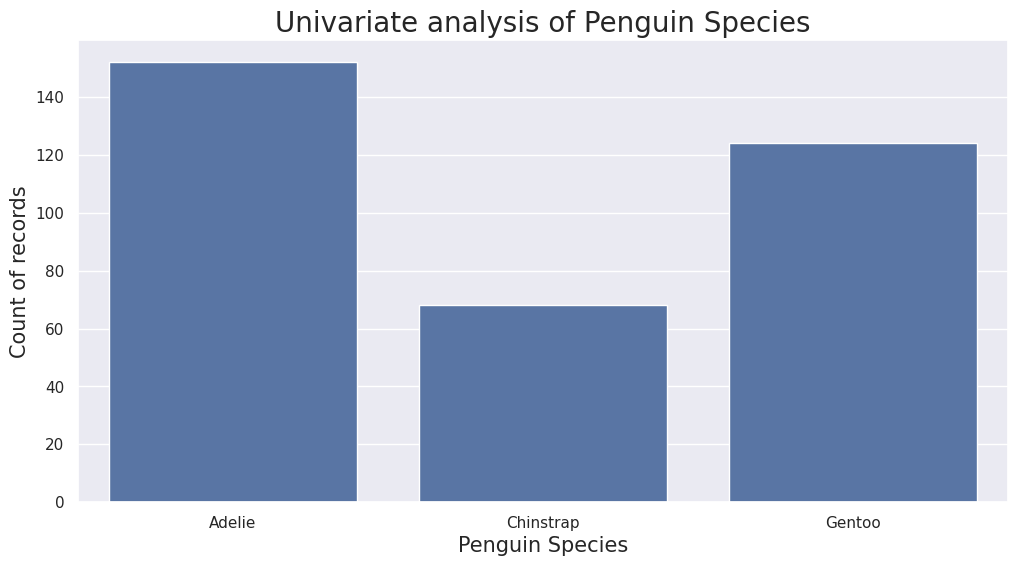

In [53]:
# case 2: advanced
plt.figure(figsize= (12,6))
ax = sns.countplot(data = penguins_data, x= penguins_data['species'])
ax.set_xlabel('Penguin Species',fontsize = 15)
ax.set_ylabel('Count of records',fontsize = 15)
ax.set_title('Univariate analysis of Penguin Species', fontsize= 20)

**4. Phân tích đơn biến bằng biểu đồ tròn (Pie-chart)**

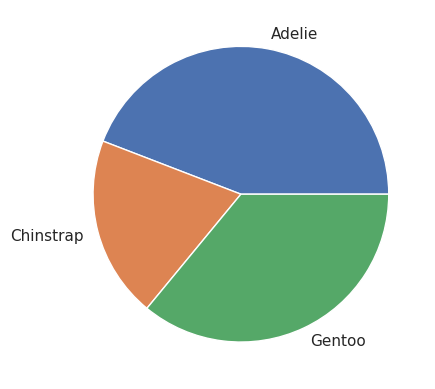

In [54]:
penguins_group = penguins_data.groupby('species').count()
penguins_group = penguins_group.reset_index()
# case 1: basic
plt.pie(penguins_group["culmen_length_mm"], labels =
                      penguins_group['species'])
plt.show()

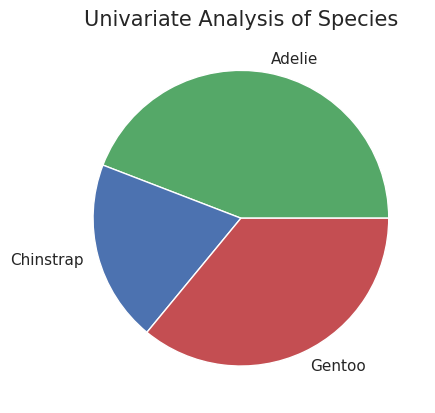

In [55]:
# case 2: advanced
cols = ['g', 'b', 'r']
plt.pie(penguins_group["culmen_length_mm"], labels =
                          penguins_group['species'],colors = cols)
plt.title('Univariate Analysis of Species', fontsize=15)
plt.show()

#### Nhiệm vụ 2: dữ liệu giá nhà (boxplot, violin plot, describe)
> Cần file `data/HousingPricesData.csv` (xem mục 1.2.2).

<Axes: xlabel='Price'>

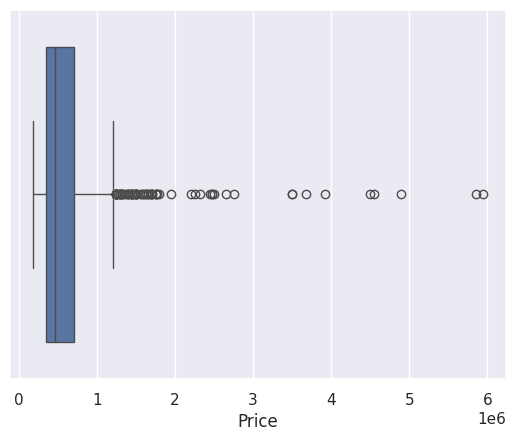

In [56]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
houseprices_data = pd.read_csv("data/HousingPricesData.csv")
houseprices_data = houseprices_data[['Zip','Price','Area','Room']]
# case 1: Create a boxplot using the boxplot method
sns.boxplot(data = houseprices_data, x= houseprices_data["Price"])

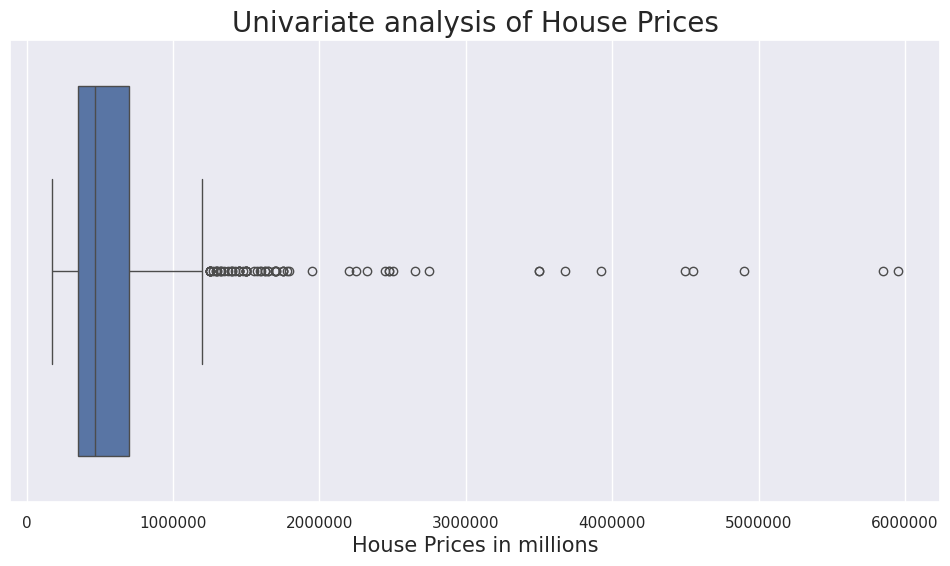

In [57]:
# case 2: advanced
plt.figure(figsize= (12,6))
ax = sns.boxplot(data = houseprices_data, x= houseprices_data["Price"])
ax.set_xlabel('House Prices in millions',fontsize = 15)
ax.set_title('Univariate analysis of House Prices', fontsize= 20)
plt.ticklabel_format(style='plain', axis='x')

<Axes: xlabel='Price'>

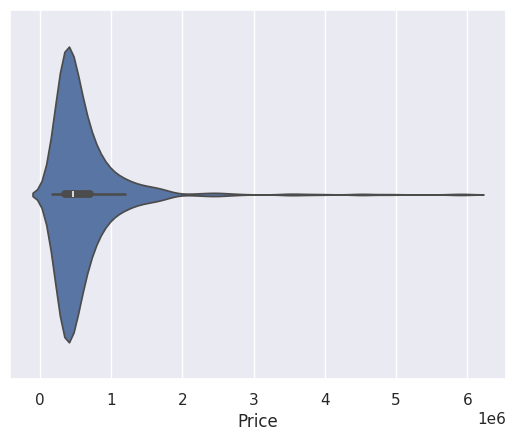

In [58]:
# case 1: basic
sns.violinplot(data = houseprices_data, x= houseprices_data["Price"])

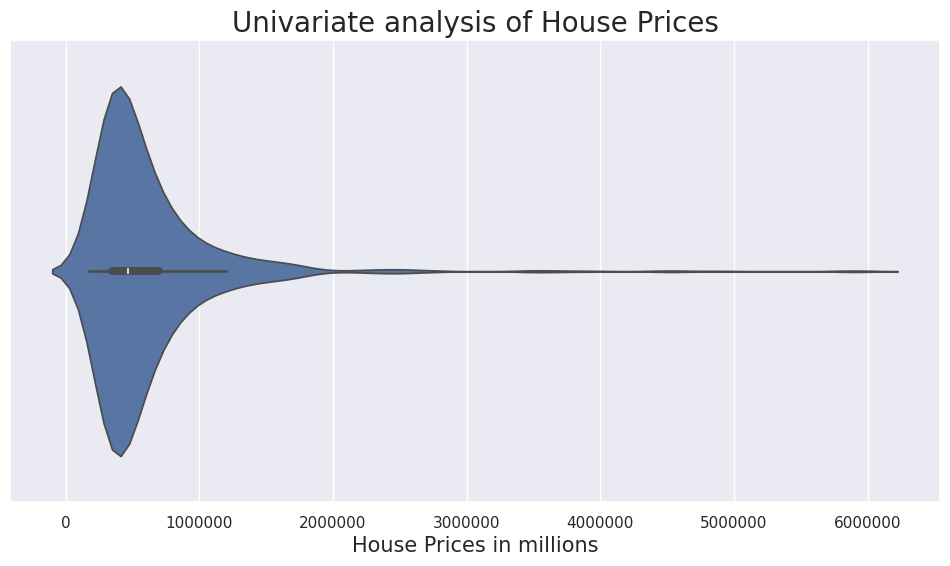

In [59]:
# case 2: advanced
plt.figure(figsize= (12,6))
ax = sns.violinplot(data = houseprices_data, x=houseprices_data["Price"])
ax.set_xlabel('House Prices in millions',fontsize = 15)
ax.set_title('Univariate analysis of House Prices', fontsize= 20)
plt.ticklabel_format(style='plain', axis='x')

In [60]:
houseprices_data.describe()

,Price,Area,Room
count,9.200000e+02,924.000000,924.000000
mean,6.220654e+05,95.952381,3.571429
std,5.389942e+05,57.447436,1.592332
min,1.750000e+05,21.000000,1.000000
25%,3.500000e+05,60.750000,3.000000
50%,4.670000e+05,83.000000,3.000000
75%,7.000000e+05,113.000000,4.000000
max,5.950000e+06,623.000000,14.000000


### Bài toán 2: phân tích hai biến
#### Nhiệm vụ 1: dữ liệu chim cánh cụt

In [61]:
import pandas as pd
import numpy as np   # [Chỉnh] cần cho np.mean ở pivot_table
import matplotlib.pyplot as plt
import seaborn as sns
penguins_data = pd.read_csv("data/penguins_size.csv")
penguins_data = penguins_data[['species','culmen_length_mm', 'body_mass_g']]

**2. Phân tích dữ liệu 2 biến dựa vào scatterplot**

<Axes: xlabel='culmen_length_mm', ylabel='body_mass_g'>

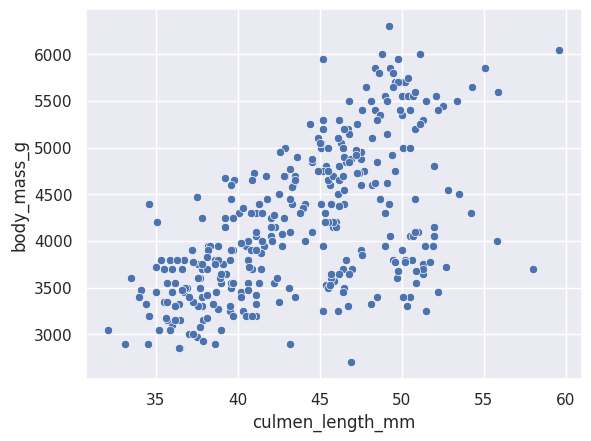

In [62]:
# case 1: basic
sns.scatterplot(data = penguins_data, x= penguins_data["culmen_length_mm"],
                                      y= penguins_data['body_mass_g'])

Text(0.5, 1.0, 'Bivariate analysis of Culmen Length and body mass')

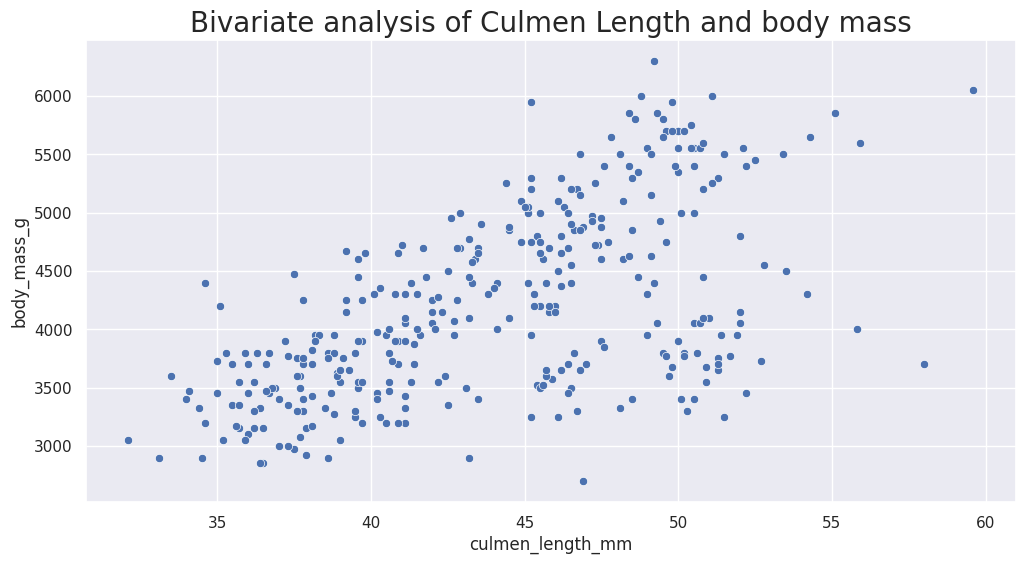

In [63]:
# case 2: advanced
plt.figure(figsize= (12,6))
ax = sns.scatterplot(data = penguins_data,
        x= penguins_data["culmen_length_mm"],
        y= penguins_data['body_mass_g'])
ax.set_title('Bivariate analysis of Culmen Length and body mass', fontsize=
20)

**3. Phân tích 2 biến dựa vào bảng crosstab/two-way**

In [64]:
# [Chỉnh] cột 'sex' không được chọn ở bước 1 của đề nên nạp lại từ file gốc
penguins_full = pd.read_csv("data/penguins_size.csv")
pd.crosstab(index= penguins_full['species'], columns= penguins_full['sex'])

sex,.,FEMALE,MALE
species,,,
Adelie,0,73,73
Chinstrap,0,34,34
Gentoo,1,58,61


**4. Phân tích 2 biến sử dụng pivot_table**

In [65]:
pd.pivot_table(penguins_data, values='culmen_length_mm',
                       index='species', aggfunc=np.mean)

/tmp/ipykernel_122/3706744655.py:1: FutureWarning: The provided callable <function mean at 0x7f7a6800cc20> is currently using DataFrameGroupBy.mean. In a future version of pandas, the provided callable will be used directly. To keep current behavior pass the string "mean" instead.
  pd.pivot_table(penguins_data, values='culmen_length_mm',


,culmen_length_mm
species,
Adelie,38.791391
Chinstrap,48.833824
Gentoo,47.504878


**5. Phân tích 2 biến sử dụng pairplot**

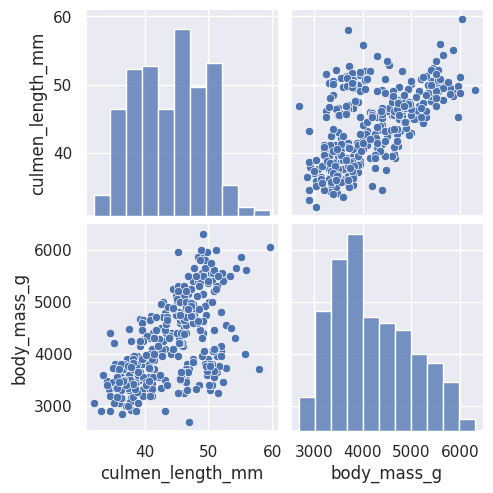

In [66]:
import seaborn as sns
sns.pairplot( data = penguins_data)

### Bài toán 3: công cụ EDA tự động
#### Nhiệm vụ 1: ydata_profiling (trước đây là pandas_profiling) trên dữ liệu Customer Personality Analysis

In [67]:
import pandas as pd
from ydata_profiling import ProfileReport
# [Chỉnh] sep='\t' cho đúng định dạng file Marketing Campaign
marketing_data = pd.read_csv("data/marketing_campaign.csv", sep='\t', encoding='utf-8-sig')
# Create an Automated EDA report using the ProfileReport class in the
# ydata_profiling library. Use the to_file method to output the report to an HTML file
profile = ProfileReport(marketing_data)
profile.to_file("Reports/profile_output.html")

/usr/local/lib/python3.12/dist-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


/tmp/ipykernel_122/28472545.py:2: DeprecationWarning: 
    `import ydata_profiling` is deprecated and will not receive more updates. 
    Please install fg-data-profiling via `pip install fg-data-profiling` and use `import data_profiling` instead.
    
  from ydata_profiling import ProfileReport


Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]

Summarize dataset:   0%|          | 0/34 [00:00<?, ?it/s, Describe variable: ID]

  0%|          | 0/29 [00:00<?, ?it/s]

...

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML: 100%|██████████| 1/1 [00:02<00:00,  2.06s/it]

Render HTML: 100%|██████████| 1/1 [00:02<00:00,  2.06s/it]

Export report to file:   0%|          | 0/1 [00:00<?, ?it/s]

Export report to file: 100%|██████████| 1/1 [00:00<00:00, 21.76it/s]

#### Nhiệm vụ 2: dtale trên dữ liệu Marketing Campaign
> dtale mở một web-server và trình duyệt, nên ô này không chạy tự động trong notebook báo cáo (chạy trên máy: `pip install dtale`).

In [ ]:
import pandas as pd
import dtale
marketing_data = pd.read_csv("data/marketing_campaign.csv", sep='\t', encoding='utf-8-sig')
dtale.show(marketing_data).open_browser()

### 1.3.3. Bài tập thực hành 1 — SweetViz trên tập Marketing Campaign
**Tính năng chính của SweetViz:**
- Tạo báo cáo HTML tương tác chỉ với một dòng lệnh `sv.analyze(df)`; mỗi biến có thống kê (số lượng, thiếu, distinct, mean/median/std…) cùng biểu đồ phân bố.
- Hiển thị ma trận tương quan/liên hệ giữa các biến, kể cả biến phân loại (hệ số tương quan, uncertainty coefficient, correlation ratio).
- So sánh hai tập dữ liệu bằng `sv.compare([train, 'Train'], [test, 'Test'])` hoặc so sánh hai nhóm con bằng `sv.compare_intra(df, df['Education']=='PhD', ['PhD','Others'])`.
- Phân tích theo biến mục tiêu (`target_feat='Response'`) để xem mối quan hệ của từng biến với nhãn.
- Xuất báo cáo bằng `show_html(...)` (file HTML độc lập) hoặc `show_notebook()`.

**Cách sử dụng:** `pip install sweetviz` → `report = sv.analyze(df)` → `report.show_html('file.html')`.

In [68]:
import sweetviz as sv
marketing_data = pd.read_csv("data/marketing_campaign.csv", sep='\t', encoding='utf-8-sig')
report = sv.analyze(marketing_data)
report.show_html("Reports/sweetviz_report.html", open_browser=False)

                                             |          | [  0%]   00:00 -> (? left)

[Summarizing dataframe]                      |          | [  0%]   00:00 -> (? left)

Feature: ID                                  |▎         | [  3%]   00:00 -> (00:00 left)

Feature: ID                                  |▋         | [  7%]   00:01 -> (00:16 left)

Feature: Year_Birth                          |▋         | [  7%]   00:01 -> (00:16 left)

...

[Step 2/3] Processing Pairwise Features      |          | [  0%]   00:00 -> (? left)    

[Step 3/3] Generating associations graph     |          | [  0%]   00:00 -> (? left)

Done! Use 'show' commands to display/save.   |          | [  0%]   00:02 -> (? left)

Done! Use 'show' commands to display/save.   |██████████| [100%]   00:02 -> (00:00 left)

Report Reports/sweetviz_report.html was generated.


### 1.3.4. Bài tập thực hành 2 — AutoViz trên tập Marketing Campaign
**Tính năng chính của AutoViz:**
- Tự động vẽ nhiều loại biểu đồ (histogram, boxplot, scatter, pairplot, heatmap tương quan, violin, biểu đồ cột cho biến phân loại…) chỉ với một lệnh `AV.AutoViz(file)`; công cụ tự chọn biểu đồ phù hợp theo kiểu dữ liệu.
- Tự phát hiện và xử lý một số vấn đề dữ liệu như cột có tỉ lệ thiếu cao, cột hằng số, cột trùng, ngoại lai; có thể chỉ định biến mục tiêu `depVar`.
- Với tập lớn có thể lấy mẫu (`max_rows_analyzed`, `max_cols_analyzed`) để chạy nhanh; có thể xuất biểu đồ ra thư mục (`chart_format='png'`/`'html'`).

**Cách sử dụng:** `pip install autoviz` → `from autoviz.AutoViz_Class import AutoViz_Class` → `AV = AutoViz_Class(); AV.AutoViz('file.csv', sep='\t')`.
> AutoViz mở nhiều biểu đồ trong trình duyệt/notebook và thường xung đột phiên bản thư viện, nên ô code dưới đây chạy trên máy cá nhân.

In [ ]:
from autoviz.AutoViz_Class import AutoViz_Class
AV = AutoViz_Class()
dft = AV.AutoViz("data/marketing_campaign.csv", sep='\t')